In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42

In [23]:
df = pd.read_csv("heart.csv")

print(df.shape)
df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [24]:
print(df.info())
print(df.describe())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
print("\nClass balance:\n", df["HeartDisease"].value_counts(normalize=True))


print("\nCholesterol == 0:", (df["Cholesterol"] == 0).sum())
print("RestingBP == 0:", (df["RestingBP"] == 0).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB
None
              Age   RestingBP  Cholesterol   FastingBS       MaxHR  \
count  918.000000  918.000000   918.000000  918.000000  918.000000   
mean    53.510893  132.396514   198.799564    0.233115  1

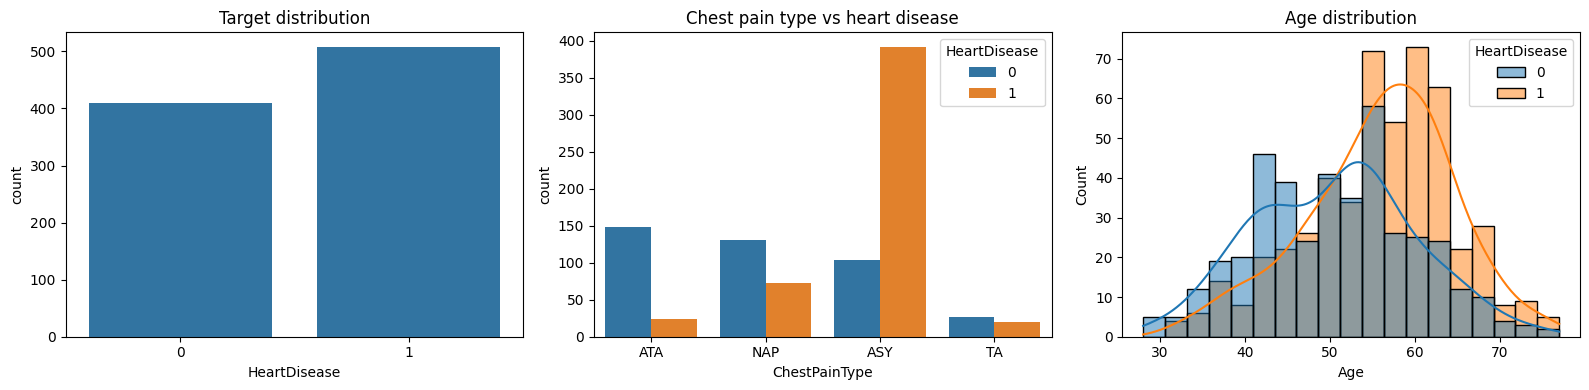

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="HeartDisease", data=df, ax=axes[0])
axes[0].set_title("Target distribution")
sns.countplot(x="ChestPainType", hue="HeartDisease", data=df, ax=axes[1])
axes[1].set_title("Chest pain type vs heart disease")
sns.histplot(data=df, x="Age", hue="HeartDisease", kde=True, ax=axes[2])
axes[2].set_title("Age distribution")
plt.tight_layout()
plt.show()

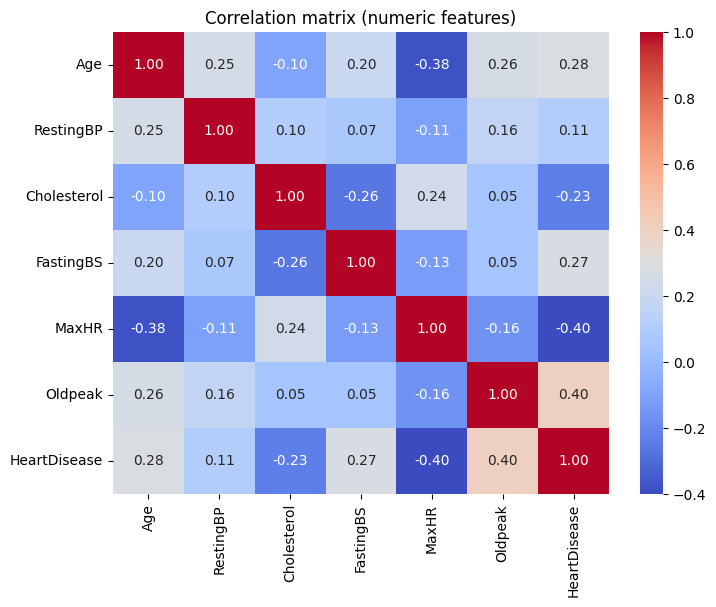

In [32]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix (numeric features)")
plt.show()

(918, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB
None
              Age   RestingBP  Cholesterol   FastingBS       MaxHR  \
count  918.000000  918.000000   918.000000  918.000000  918.000000   
mean    53.510893  132.396514   198.799564    0

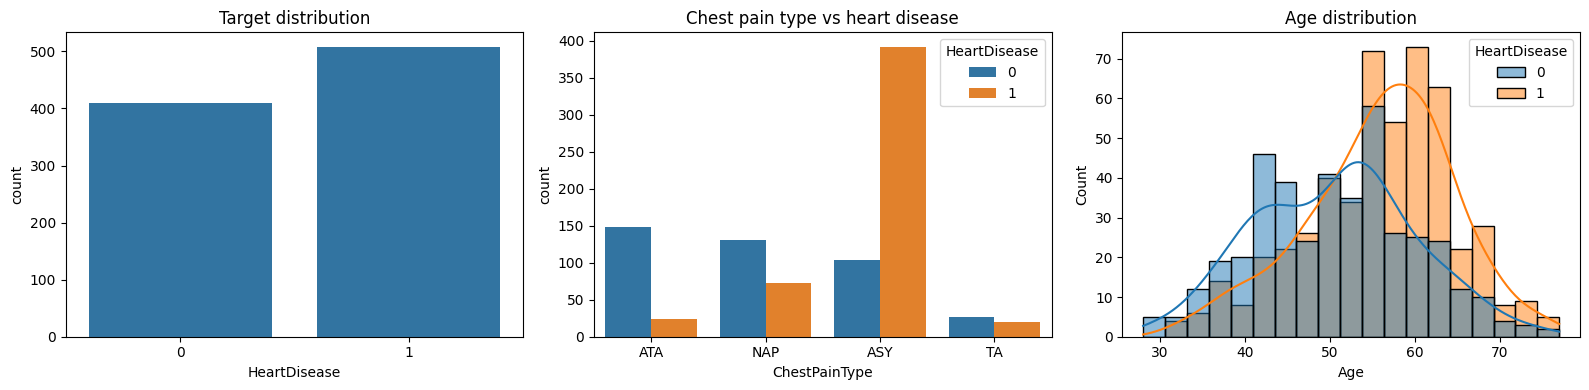

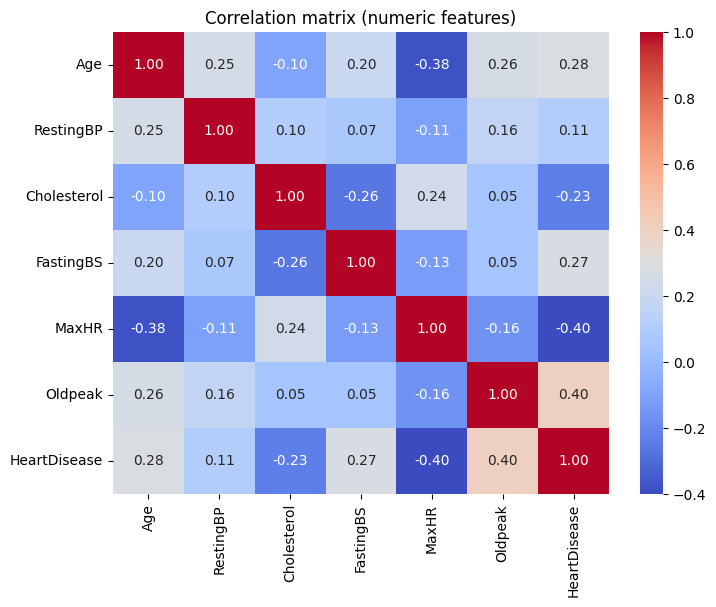

Train: (734, 11) Test: (184, 11)
Trained: Logistic Regression
Trained: Random Forest
Trained: SVM (RBF)

===== Logistic Regression =====
               precision    recall  f1-score   support

       Normal       0.89      0.85      0.87        82
Heart Disease       0.89      0.91      0.90       102

     accuracy                           0.89       184
    macro avg       0.89      0.88      0.88       184
 weighted avg       0.89      0.89      0.89       184


===== Random Forest =====
               precision    recall  f1-score   support

       Normal       0.85      0.87      0.86        82
Heart Disease       0.89      0.87      0.88       102

     accuracy                           0.87       184
    macro avg       0.87      0.87      0.87       184
 weighted avg       0.87      0.87      0.87       184


===== SVM (RBF) =====
               precision    recall  f1-score   support

       Normal       0.87      0.83      0.85        82
Heart Disease       0.87      0.90  

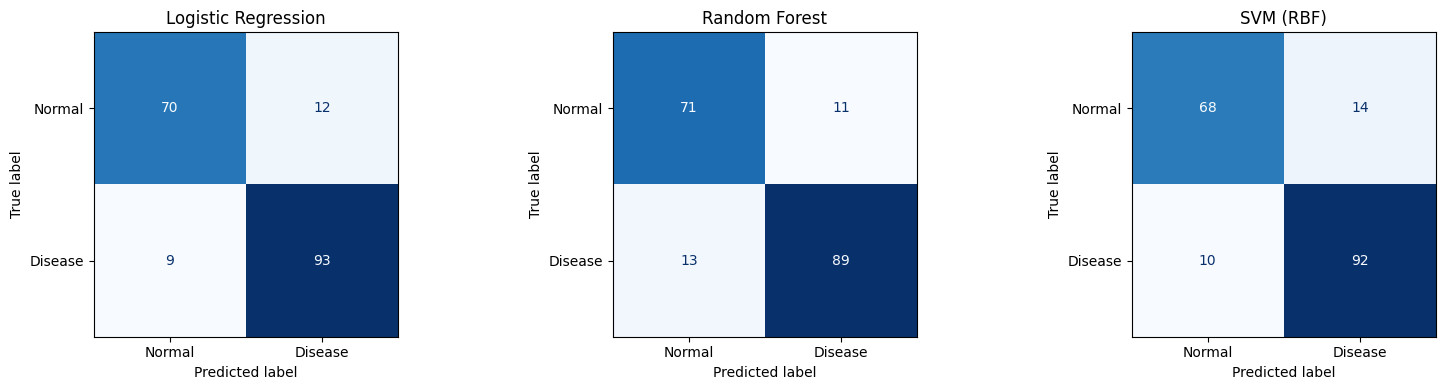

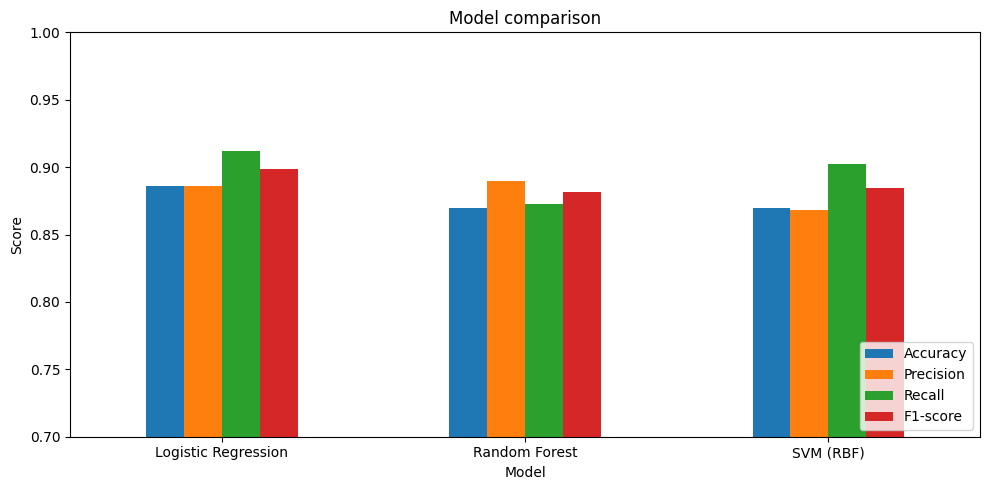

Best model by F1-score: Logistic Regression
Accuracy          0.8859
Precision         0.8857
Recall            0.9118
F1-score          0.8986
ROC-AUC           0.9323
CV F1 (5-fold)    0.8671
Name: Logistic Regression, dtype: float64


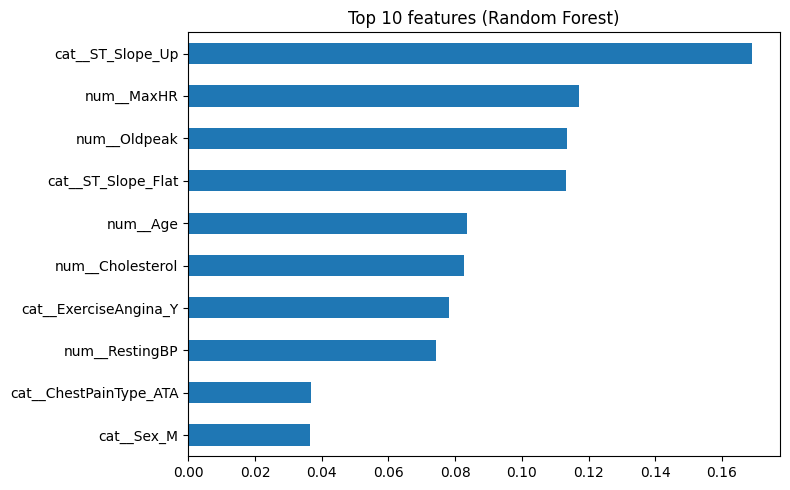

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42


df = pd.read_csv("heart.csv")
print(df.shape)
df.head()


print(df.info())
print(df.describe())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
print("\nClass balance:\n", df["HeartDisease"].value_counts(normalize=True))
print("\nCholesterol == 0:", (df["Cholesterol"] == 0).sum())
print("RestingBP == 0:", (df["RestingBP"] == 0).sum())


fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="HeartDisease", data=df, ax=axes[0])
axes[0].set_title("Target distribution")
sns.countplot(x="ChestPainType", hue="HeartDisease", data=df, ax=axes[1])
axes[1].set_title("Chest pain type vs heart disease")
sns.histplot(data=df, x="Age", hue="HeartDisease", kde=True, ax=axes[2])
axes[2].set_title("Age distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix (numeric features)")
plt.show()


df_clean = df.copy()
df_clean["Cholesterol"] = df_clean["Cholesterol"].replace(0, np.nan)
df_clean["RestingBP"] = df_clean["RestingBP"].replace(0, np.nan)

X = df_clean.drop(columns="HeartDisease")
y = df_clean["HeartDisease"]

numeric_features = ["Age", "RestingBP", "Cholesterol", "FastingBS", "MaxHR", "Oldpeak"]
categorical_features = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)


models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE),
}

pipelines = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print(f"Trained: {name}")


results = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1").mean()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "CV F1 (5-fold)": cv_f1,
    })

    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=["Normal", "Heart Disease"]))

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df


fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, pipe) in zip(axes, pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Disease"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()


results_df[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(10, 5), rot=0)
plt.title("Model comparison")
plt.ylabel("Score")
plt.ylim(0.7, 1.0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_model = results_df["F1-score"].idxmax()
print(f"Best model by F1-score: {best_model}")
print(results_df.loc[best_model])


rf = pipelines["Random Forest"]
feat_names = rf.named_steps["prep"].get_feature_names_out()
importances = pd.Series(rf.named_steps["model"].feature_importances_, index=feat_names)
importances.sort_values().tail(10).plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 features (Random Forest)")
plt.tight_layout()
plt.show()

In [27]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE),
}

pipelines = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Random Forest
Trained: SVM (RBF)


In [28]:
results = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1").mean()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "CV F1 (5-fold)": cv_f1,
    })

    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=["Normal", "Heart Disease"]))

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df


===== Logistic Regression =====
               precision    recall  f1-score   support

       Normal       0.89      0.85      0.87        82
Heart Disease       0.89      0.91      0.90       102

     accuracy                           0.89       184
    macro avg       0.89      0.88      0.88       184
 weighted avg       0.89      0.89      0.89       184


===== Random Forest =====
               precision    recall  f1-score   support

       Normal       0.85      0.87      0.86        82
Heart Disease       0.89      0.87      0.88       102

     accuracy                           0.87       184
    macro avg       0.87      0.87      0.87       184
 weighted avg       0.87      0.87      0.87       184


===== SVM (RBF) =====
               precision    recall  f1-score   support

       Normal       0.87      0.83      0.85        82
Heart Disease       0.87      0.90      0.88       102

     accuracy                           0.87       184
    macro avg       0.87     

,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV F1 (5-fold)
Model,,,,,,
Logistic Regression,0.8859,0.8857,0.9118,0.8986,0.9323,0.8671
Random Forest,0.8696,0.8900,0.8725,0.8812,0.9289,0.8736
SVM (RBF),0.8696,0.8679,0.9020,0.8846,0.9360,0.8768


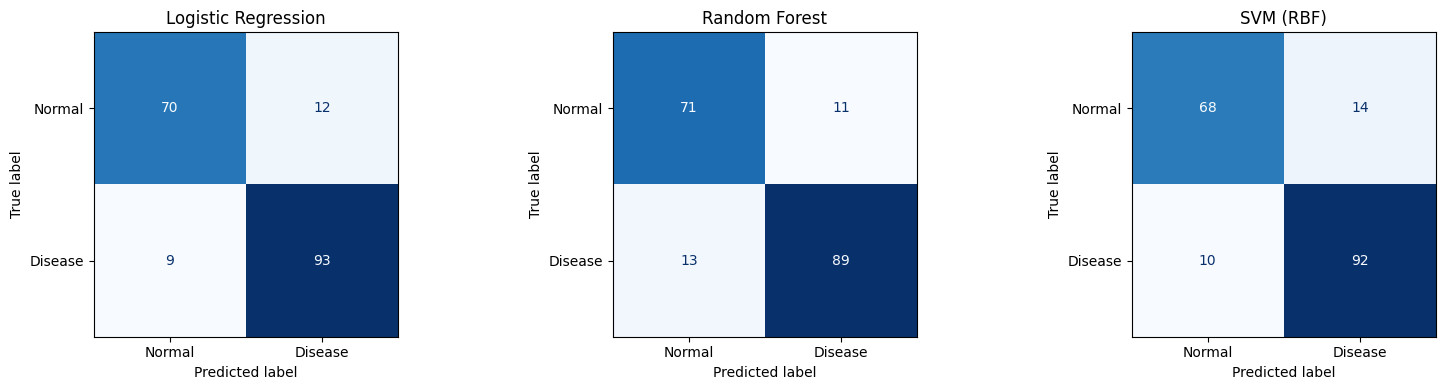

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, pipe) in zip(axes, pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Disease"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

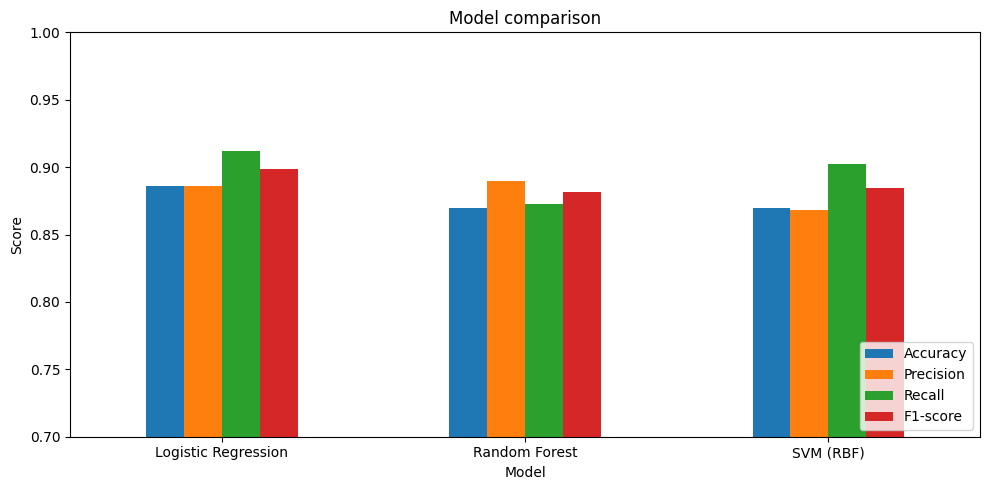

Best model by F1-score: Logistic Regression
Accuracy          0.8859
Precision         0.8857
Recall            0.9118
F1-score          0.8986
ROC-AUC           0.9323
CV F1 (5-fold)    0.8671
Name: Logistic Regression, dtype: float64


In [30]:
results_df[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(10, 5), rot=0)
plt.title("Model comparison")
plt.ylabel("Score")
plt.ylim(0.7, 1.0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_model = results_df["F1-score"].idxmax()
print(f"Best model by F1-score: {best_model}")
print(results_df.loc[best_model])

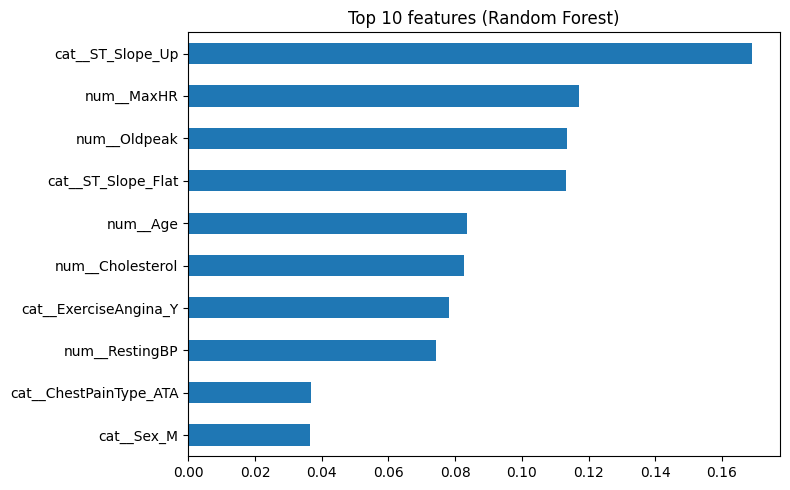

In [31]:
rf = pipelines["Random Forest"]
feat_names = rf.named_steps["prep"].get_feature_names_out()
importances = pd.Series(rf.named_steps["model"].feature_importances_, index=feat_names)
importances.sort_values().tail(10).plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 features (Random Forest)")
plt.tight_layout()
plt.show()

RESULTS SUMMARY (test set)


,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV F1 (5-fold)
Model,,,,,,
Logistic Regression,0.8859,0.8857,0.9118,0.8986,0.9323,0.8671
Random Forest,0.8696,0.8900,0.8725,0.8812,0.9289,0.8736
SVM (RBF),0.8696,0.8679,0.9020,0.8846,0.9360,0.8768



Ranking per metric (1 = best):


,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV F1 (5-fold)
Model,,,,,,
Logistic Regression,1,2,1,1,2,3
Random Forest,2,1,3,3,3,2
SVM (RBF),2,3,2,2,1,1


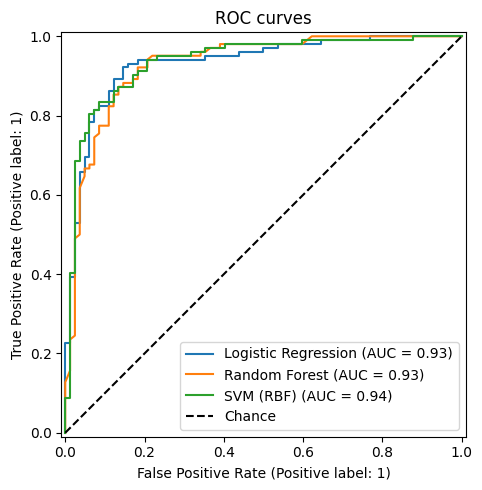


BEST MODEL: Logistic Regression
Accuracy  : 0.886
Precision : 0.886
Recall    : 0.912
F1-score  : 0.899
ROC-AUC   : 0.932
CV F1 (5-fold): 0.867

Confusion matrix: TP=93, TN=70, FP=12, FN=9

Justification:
- Logistic Regression achieved the highest F1-score (0.899), balancing precision and recall.
- It outperformed Random Forest by 0.017 in F1-score (accuracy: 0.886 vs 0.870).
- It outperformed SVM (RBF) by 0.014 in F1-score (accuracy: 0.886 vs 0.870).
- Its recall of 0.912 means it correctly identified 93 of 102 patients with heart disease; only 9 were missed (false negatives), which matters most in a medical setting.
- Cross-validated F1 (0.867) is close to the test F1, suggesting the result is stable and not due to one lucky split.


In [ ]:
from sklearn.metrics import RocCurveDisplay


print("=" * 70)
print("RESULTS SUMMARY (test set)")
print("=" * 70)
display(results_df)   


ranking = results_df.rank(ascending=False).astype(int)
print("\nRanking per metric (1 = best):")
display(ranking)


fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in pipelines.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_title("ROC curves")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


best = results_df["F1-score"].idxmax()
b = results_df.loc[best]

print("\n" + "=" * 70)
print(f"BEST MODEL: {best}")
print("=" * 70)
print(f"Accuracy  : {b['Accuracy']:.3f}")
print(f"Precision : {b['Precision']:.3f}")
print(f"Recall    : {b['Recall']:.3f}")
print(f"F1-score  : {b['F1-score']:.3f}")
print(f"ROC-AUC   : {b['ROC-AUC']:.3f}")
print(f"CV F1 (5-fold): {b['CV F1 (5-fold)']:.3f}")

cm = confusion_matrix(y_test, pipelines[best].predict(X_test))
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix: TP={tp}, TN={tn}, FP={fp}, FN={fn}")

others = [m for m in results_df.index if m != best]
print("\nJustification:")
print(f"- {best} achieved the highest F1-score ({b['F1-score']:.3f}), "
      f"balancing precision and recall.")
for m in others:
    diff = b["F1-score"] - results_df.loc[m, "F1-score"]
    print(f"- It outperformed {m} by {diff:.3f} in F1-score "
          f"(accuracy: {b['Accuracy']:.3f} vs {results_df.loc[m, 'Accuracy']:.3f}).")
print(f"- Its recall of {b['Recall']:.3f} means it correctly identified "
      f"{tp} of {tp + fn} patients with heart disease; only {fn} were missed "
      f"(false negatives), which matters most in a medical setting.")
print(f"- Cross-validated F1 ({b['CV F1 (5-fold)']:.3f}) is close to the test F1, "
      f"suggesting the result is stable and not due to one lucky split.")
if results_df["Recall"].idxmax() != best:
    print(f"- Note: {results_df['Recall'].idxmax()} had the highest recall "
          f"({results_df['Recall'].max():.3f}). If minimising missed patients is the "
          f"priority, it could be preferred.")